#Loading the dataset

This notebook explores the supplied sample of 2019 New York City Airbnb listings. I will inspect and clean the data, explore individual variables and relationships, and summarise findings relevant to listing prices

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

uploaded = files.upload()

df = pd.read_csv("Assignment_Dataset.csv.csv")
df.head(10)

Saving Assignment_Dataset.csv.csv to Assignment_Dataset.csv (1).csv


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,32785169,2 Bedroom Refuge with Private Bath & Living Room,20433973,Julia,Bronx,City Island,40.83988,-73.78287,Private room,95,1,6,2019-06-17,1.65,2,359
1,34399984,Two private rooms,259690766,Souadou,Bronx,Belmont,40.85648,-73.88501,Private room,95,2,4,2019-07-01,2.35,1,325
2,36379669,Shared living space in the Bronx!,44378432,Bryan,Bronx,Pelham Bay,40.84735,-73.83095,Shared room,50,1,0,NaN,NaN,1,88
3,35249458,Light-filled comfortable entire apartment,264809787,Kurt,Bronx,Concourse Village,40.82778,-73.91516,Entire home/apt,75,3,2,2019-06-21,2.00,1,253
4,30253236,SedaOn2 Dance Studio,140862407,Angelie,Bronx,Westchester Square,40.84378,-73.84469,Entire home/apt,670,1,2,2019-03-31,0.34,1,178
5,16506121,Beautifully private furnished room,108464471,Jeremiah,Bronx,Longwood,40.81790,-73.91456,Private room,100,6,0,NaN,NaN,1,365
6,19974905,Esteem's Place,141615596,Esteem,Bronx,Parkchester,40.83805,-73.85867,Shared room,26,1,18,2019-04-23,0.78,2,342
7,12345615,Natural light comfortable room!,52196858,Danny,Bronx,Parkchester,40.83648,-73.85812,Private room,59,1,120,2019-07-02,3.11,2,336
8,16476956,Newly renovated & Fully Furnished Super clean,51065605,Charles,Bronx,Port Morris,40.80743,-73.92971,Entire home/apt,115,5,7,2019-07-01,0.23,1,7
9,33363084,E community that is commercially (Website hidd...,242175033,Alex,Bronx,Allerton,40.86003,-73.86584,Entire home/apt,60,1,28,2019-07-02,8.32,1,74


#Inspect the structure

I inspect the dataset’s dimensions, column types and numerical summaries before cleaning.

In [3]:
print("Shape:", df.shape)
df.info()
df.describe()

Shape: (4889, 16)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4889 entries, 0 to 4888
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              4889 non-null   int64  
 1   name                            4886 non-null   object 
 2   host_id                         4889 non-null   int64  
 3   host_name                       4889 non-null   object 
 4   neighbourhood_group             4889 non-null   object 
 5   neighbourhood                   4889 non-null   object 
 6   latitude                        4889 non-null   float64
 7   longitude                       4889 non-null   float64
 8   room_type                       4889 non-null   object 
 9   price                           4889 non-null   int64  
 10  minimum_nights                  4889 non-null   int64  
 11  number_of_reviews               4889 non-null   int64  
 12  last_review     

,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
count,4.889000e+03,4.889000e+03,4889.000000,4889.000000,4889.00000,4889.000000,4889.000000,3879.000000,4889.000000,4889.000000
mean,1.902666e+07,6.697190e+07,40.728549,-73.952288,155.46533,6.825731,23.643485,1.399588,6.830027,115.726529
std,1.091048e+07,7.795207e+07,0.054869,0.045684,286.86715,17.227167,43.762044,1.889328,31.722288,132.295573
min,5.803000e+03,2.787000e+03,40.522930,-74.212380,0.00000,1.000000,0.000000,0.010000,1.000000,0.000000
25%,9.497513e+06,8.138665e+06,40.689760,-73.982950,70.00000,1.000000,1.000000,0.200000,1.000000,0.000000
50%,1.972056e+07,3.028359e+07,40.723060,-73.955720,106.00000,3.000000,5.000000,0.750000,1.000000,50.000000
75%,2.913442e+07,1.072729e+08,40.763060,-73.936710,179.00000,5.000000,24.000000,2.025000,2.000000,235.000000
max,3.648466e+07,2.743115e+08,40.903560,-73.726000,10000.00000,365.000000,447.000000,58.500000,327.000000,365.000000


1. The dataset contains 4,889 listings and 16 columns, covering location, room type, price, reviews and availability.
2. Price ranges from $0 to $10,000. Its mean is approximately $155.47, while its median is $106, suggesting an unusually high-price distribution.
3. last_review is stored as text rather than a date. last_review and reviews_per_month each have only 3,879 non-missing entries.

#Identify numerical and categorical columns
I select columns by their stored data types to help choose suitable plots.

In [4]:
numeric_cols = list(df.select_dtypes(include="number").columns)
categorical_cols = list(df.select_dtypes(include="object").columns)

print("Numeric columns:", numeric_cols)
print("Categorical columns:", categorical_cols)

Numeric columns: ['id', 'host_id', 'latitude', 'longitude', 'price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']
Categorical columns: ['name', 'host_name', 'neighbourhood_group', 'neighbourhood', 'room_type', 'last_review']


#Investigate data-quality issues

I count missing values and duplicate rows, inspect zero prices and long minimum stays, and check whether missing monthly-review values belong to listings with no reviews.

In [5]:
print("Missing values:")
print(df.isnull().sum())

print("Duplicate rows:", df.duplicated().sum())

print("Zero-price listings:")
print(df[df["price"] == 0][["id", "price", "minimum_nights"]])

print("Minimum stays above 30 nights:")
print(df[df["minimum_nights"] > 30][["id", "price", "minimum_nights"]])

print("Review counts where monthly reviews are missing:")
print(
    df[df["reviews_per_month"].isnull()]["number_of_reviews"].value_counts()
)

Missing values:
id                                   0
name                                 3
host_id                              0
host_name                            0
neighbourhood_group                  0
neighbourhood                        0
latitude                             0
longitude                            0
room_type                            0
price                                0
minimum_nights                       0
number_of_reviews                    0
last_review                       1010
reviews_per_month                 1010
calculated_host_listings_count       0
availability_365                     0
dtype: int64
Duplicate rows: 0
Zero-price listings:
            id  price  minimum_nights
107   20333471      0               2
1182  20639628      0               1
1388  18750597      0               4
3944  20933849      0               3
Minimum stays above 30 nights:
            id  price  minimum_nights
184    6400055     45              31
190   13109

There are three missing listing names and 1,010 missing values in each review-related column. Every listing with missing monthly-review data has zero recorded reviews, supporting replacement with zero. There are no fully duplicated rows, four zero-price listings and 65 listings requiring more than 30 nights.

#Clean the dataset

I replace missing names with "Unknown" to retain the listings. I fill missing monthly-review values with zero because the affected listings have no reviews, and leave missing review dates missing because inventing a date would be misleading. I exclude zero prices from price analysis, but retain long minimum stays and high prices because they could represent genuine listings.

In [6]:
df_clean = df.drop_duplicates().copy()

df_clean["name"] = df_clean["name"].fillna("Unknown")
df_clean["reviews_per_month"] = df_clean["reviews_per_month"].fillna(0)

df_clean["last_review"] = pd.to_datetime(
    df_clean["last_review"],
    errors="coerce"
)

df_clean["neighbourhood_group"] = (
    df_clean["neighbourhood_group"].str.strip()
)
df_clean["neighbourhood"] = df_clean["neighbourhood"].str.strip()
df_clean["room_type"] = df_clean["room_type"].str.strip()

df_clean = df_clean[df_clean["price"] > 0].copy()

print("Cleaned shape:", df_clean.shape)
print(df_clean.isnull().sum())
print("Review date type:", df_clean["last_review"].dtype)

Cleaned shape: (4885, 16)
id                                   0
name                                 0
host_id                              0
host_name                            0
neighbourhood_group                  0
neighbourhood                        0
latitude                             0
longitude                            0
room_type                            0
price                                0
minimum_nights                       0
number_of_reviews                    0
last_review                       1009
reviews_per_month                    0
calculated_host_listings_count       0
availability_365                     0
dtype: int64
Review date type: datetime64[ns]


#Engineer a price category

I create a price category using a function and conditionals. Prices up to $100 are labelled Budget, prices above $100 and up to $200 are Mid-range, and prices above $200 are High-price. These are chosen analysis bands, not official market categories or measures of quality.

In [7]:
def classify_price(price):
    if price <= 100:
        return "Budget"
    elif price <= 200:
        return "Mid-range"
    else:
        return "High-price"

df_clean["price_category"] = df_clean["price"].apply(classify_price)

print(df_clean[["price", "price_category"]].head(10))
print(df_clean["price_category"].value_counts())

   price price_category
0     95         Budget
1     95         Budget
2     50         Budget
3     75         Budget
4    670     High-price
5    100         Budget
6     26         Budget
7     59         Budget
8    115      Mid-range
9     60         Budget
price_category
Budget        2375
Mid-range     1672
High-price     838
Name: count, dtype: int64


#Summarise prices and create a readable plotting subset

I calculate price summaries using all cleaned listings. For selected price plots, I create a separate subset containing prices up to $500 so extreme prices do not compress the main distribution. This changes the plotted view only; the full cleaned dataset remains available for summaries and correlations.

In [8]:
print("Mean price:", df_clean["price"].mean())
print("Median price:", df_clean["price"].median())
print("Price summary:")
print(df_clean["price"].describe())

price_view = df_clean[df_clean["price"] <= 500].copy()

print("Listings shown in limited price plots:", price_view.shape[0])
print("Listings above $500:", df_clean[df_clean["price"] > 500].shape[0])

Mean price: 155.59263050153533
Median price: 107.0
Price summary:
count     4885.000000
mean       155.592631
std        286.950080
min         15.000000
25%         70.000000
50%        107.000000
75%        179.000000
max      10000.000000
Name: price, dtype: float64
Listings shown in limited price plots: 4779
Listings above $500: 106


#Univariate plot 1—price distribution

I use a histogram to explore prices up to $500. The title makes the restricted plotting range explicit.

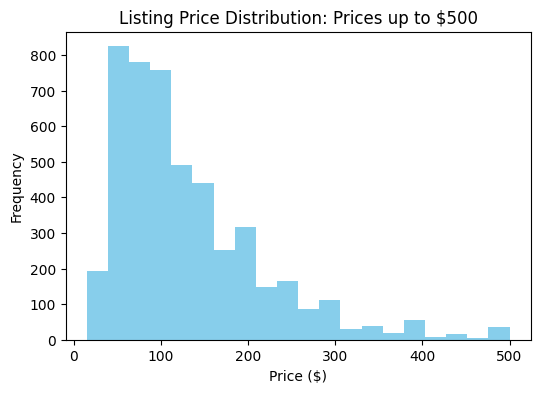

In [9]:
plt.figure(figsize=(6, 4))
plt.hist(price_view["price"], bins=20, color="skyblue")
plt.title("Listing Price Distribution: Prices up to $500")
plt.xlabel("Price ($)")
plt.ylabel("Frequency")
plt.show()

Interpretation -
The distribution is concentrated towards lower prices and extends towards higher prices. Across the full cleaned dataset, the mean of $155.59 exceeds the median of $107, supporting a right-skewed distribution. This chart excludes 106 listings above $500, so it does not show the complete price range.

#Univariate plot 2—room types

I use a count plot to compare the number of listings in each room category.

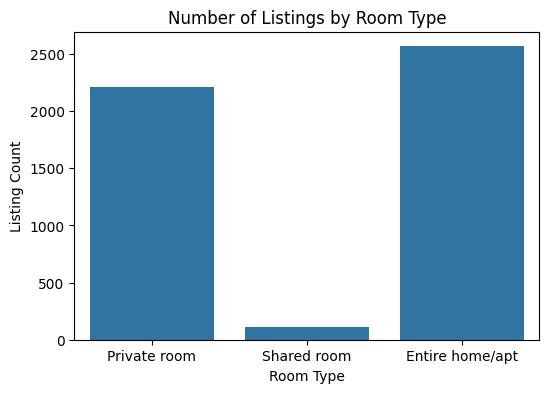

In [10]:
plt.figure(figsize=(6, 4))
sns.countplot(x="room_type", data=df_clean)
plt.title("Number of Listings by Room Type")
plt.xlabel("Room Type")
plt.ylabel("Listing Count")
plt.show()

Interpretation:
Entire homes/apartments are the largest category, with 2,566 listings, followed by 2,210 private rooms. Shared rooms account for only 109 listings, so comparisons involving them are based on a much smaller group.

#Univariate plot 3—boroughs

I compare listing counts across the five boroughs using a count plot.

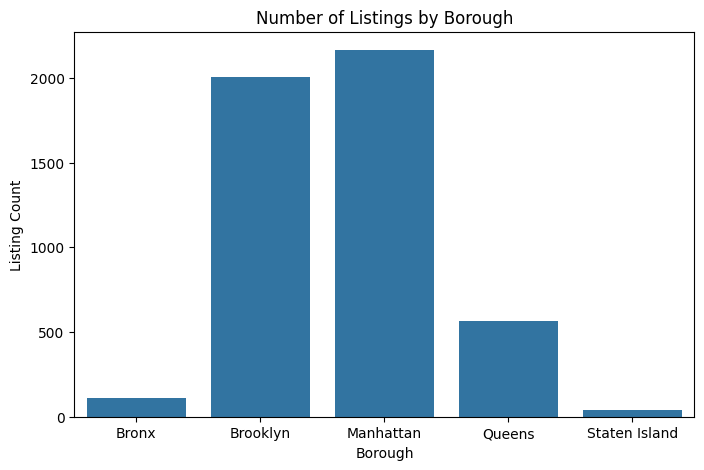

In [11]:
plt.figure(figsize=(8, 5))
sns.countplot(x="neighbourhood_group", data=df_clean)
plt.title("Number of Listings by Borough")
plt.xlabel("Borough")
plt.ylabel("Listing Count")
plt.show()

Interpretation:
Manhattan and Brooklyn dominate this sample, with 2,165 and 2,008 listings respectively. Queens has 567, the Bronx 108 and Staten Island 37. Findings for Staten Island therefore have much less sample support.

#Univariate plot 4—annual availability

I use a histogram to explore the number of days listings are available during the year.

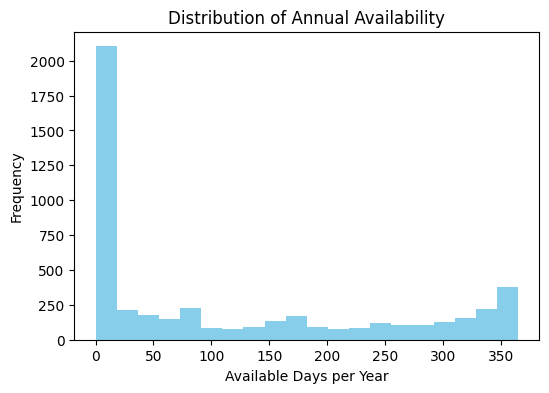

In [12]:
plt.figure(figsize=(6, 4))
plt.hist(df_clean["availability_365"], bins=20, color="skyblue")
plt.title("Distribution of Annual Availability")
plt.xlabel("Available Days per Year")
plt.ylabel("Frequency")
plt.show()

Interpretation:
Annual availability varies substantially, from zero to 365 days, with a median of 50 days. Availability does not directly measure bookings or occupancy: unavailable days may reflect bookings, blocked calendars or other reasons.

#Bivariate plot 1—price by borough

I use a box plot to compare price distributions across boroughs, displaying listings priced up to $500.

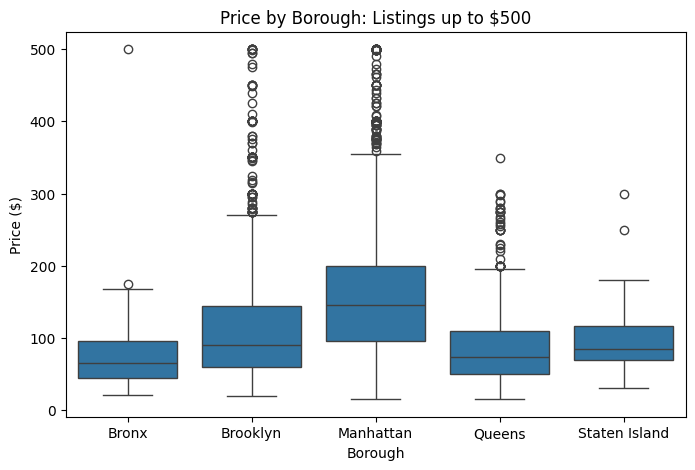

                          price             
                           mean median count
neighbourhood_group                         
Bronx                 82.611111   65.0   108
Brooklyn             121.871514   90.0  2008
Manhattan            205.782448  150.0  2165
Queens               100.015873   75.0   567
Staten Island        113.567568   85.0    37


In [13]:
plt.figure(figsize=(8, 5))
sns.boxplot(
    x="neighbourhood_group",
    y="price",
    data=price_view
)
plt.title("Price by Borough: Listings up to $500")
plt.xlabel("Borough")
plt.ylabel("Price ($)")
plt.show()

print(
    df_clean.groupby("neighbourhood_group").agg({
        "price": ["mean", "median", "count"]
    })
)

Interpretation:
The full-data median price is highest in Manhattan at $150, followed by Brooklyn at $90. The medians are $85 in Staten Island, $75 in Queens and $65 in the Bronx. Borough comparisons also reflect differences in the types of listings available, so location alone does not explain these differences.

#Bivariate plot 2—price by room type

I compare price distributions across room types using a box plot and calculate full-data summaries.

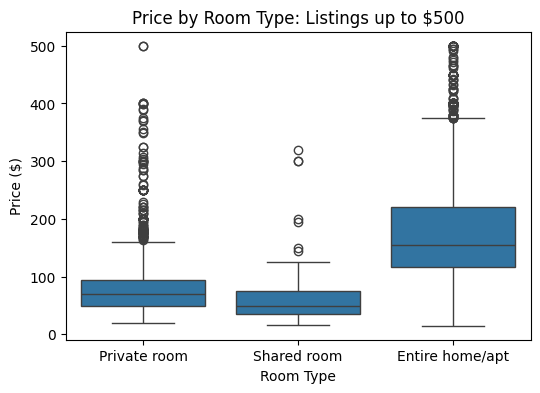

                      price             
                       mean median count
room_type                               
Entire home/apt  215.528449  160.0  2566
Private room      90.108597   70.0  2210
Shared room       72.330275   50.0   109


In [14]:
plt.figure(figsize=(6, 4))
sns.boxplot(x="room_type", y="price", data=price_view)
plt.title("Price by Room Type: Listings up to $500")
plt.xlabel("Room Type")
plt.ylabel("Price ($)")
plt.show()

print(
    df_clean.groupby("room_type").agg({
        "price": ["mean", "median", "count"]
    })
)

Interpretation:
Entire homes/apartments have the highest full-data median price at $160, compared with $70 for private rooms and $50 for shared rooms. Their mean prices are also higher. Room type is therefore a useful grouping variable for price comparisons, although this analysis does not establish causation.

#Multivariate plot 3—correlation heatmap

I create the numeric correlation heatmap requested in the assignment. I also print correlations with price to identify the strongest relationship other than price’s correlation with itself.

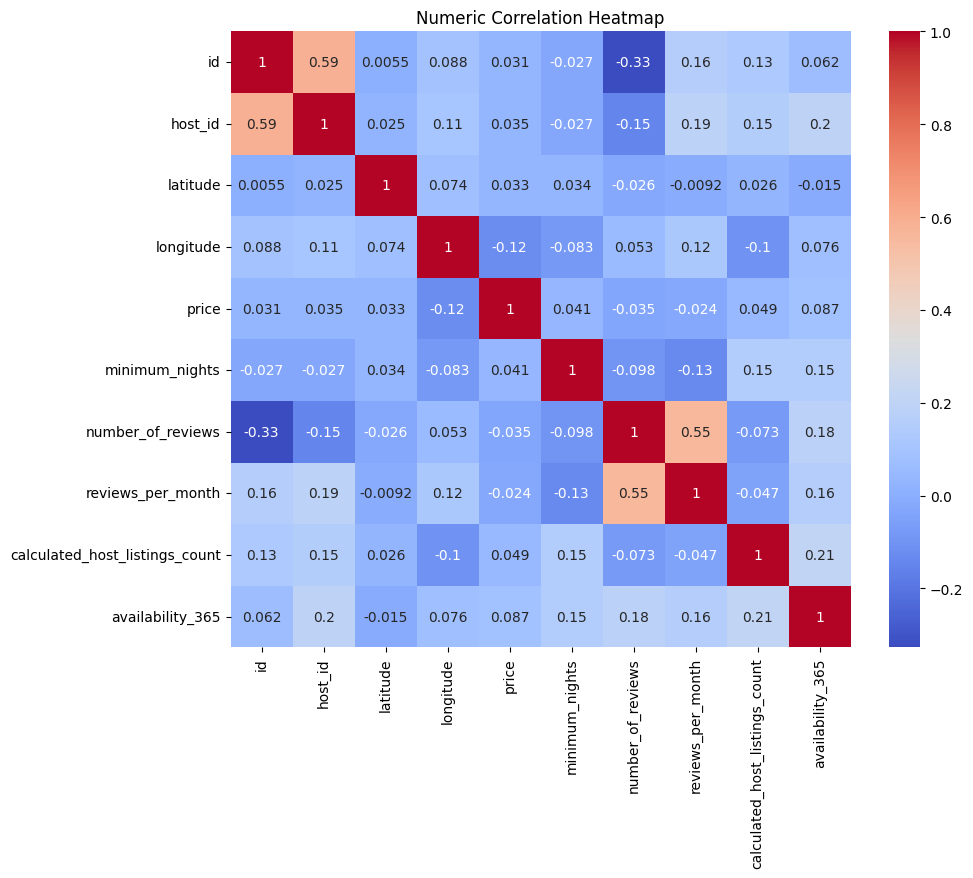

id                                0.031291
host_id                           0.035485
latitude                          0.033358
longitude                        -0.122854
price                             1.000000
minimum_nights                    0.040627
number_of_reviews                -0.035463
reviews_per_month                -0.024260
calculated_host_listings_count    0.048787
availability_365                  0.086517
Name: price, dtype: float64


In [15]:
plt.figure(figsize=(10, 8))
sns.heatmap(
    df_clean.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm"
)
plt.title("Numeric Correlation Heatmap")
plt.show()

print(df_clean.corr(numeric_only=True)["price"])

Interpretation:
Longitude has the largest absolute correlation with price among the other numeric columns, at approximately −0.123. This is a weak negative linear relationship, while availability has a smaller positive correlation of approximately 0.087. IDs are identifiers rather than meaningful measurements, and the heatmap does not directly capture categorical differences such as room type or borough.

#Multivariate plot 4—availability, price and room type

I reuse the scatter-plot method with hue from Lab 4 to examine three variables: availability, price and room type. I also summarise prices by borough and room type to compare similar listing categories.

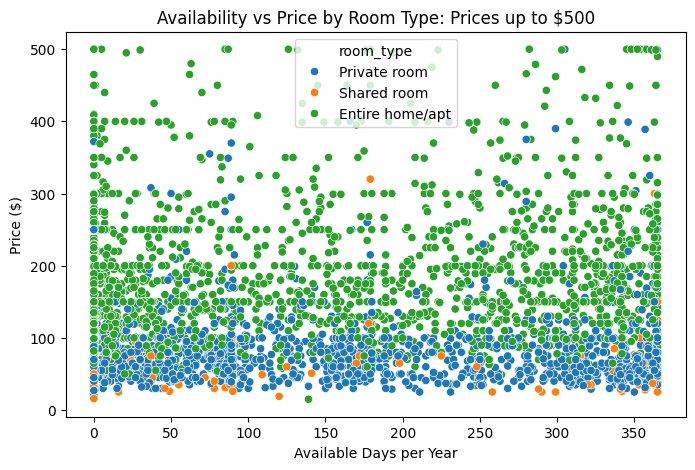

                                     price      
                                    median count
neighbourhood_group room_type                   
Bronx               Entire home/apt   99.0    42
                    Private room      50.0    64
                    Shared room       38.0     2
Brooklyn            Entire home/apt  145.0   946
                    Private room      64.0  1023
                    Shared room       35.0    39
Manhattan           Entire home/apt  190.0  1347
                    Private room      90.0   768
                    Shared room       69.0    50
Queens              Entire home/apt  121.0   208
                    Private room      60.0   342
                    Shared room       45.0    17
Staten Island       Entire home/apt  105.0    23
                    Private room      55.0    13
                    Shared room       75.0     1


In [16]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    x="availability_365",
    y="price",
    hue="room_type",
    data=price_view
)
plt.title("Availability vs Price by Room Type: Prices up to $500")
plt.xlabel("Available Days per Year")
plt.ylabel("Price ($)")
plt.show()

print(
    df_clean.groupby(["neighbourhood_group", "room_type"]).agg({
        "price": ["median", "count"]
    })
)

Interpretation:
The scatter plot compares prices across availability levels while distinguishing room types by colour. The full-data correlation between availability and price is only about 0.087, so it provides little evidence of a strong overall linear relationship. Grouped medians also show that Manhattan’s entire homes/apartments have a median price of $190, compared with $145 in Brooklyn and $121 in Queens.

#Verify the final dataset

I check the final dataset’s dimensions, missing values and engineered column before drawing conclusions.

In [17]:
print("Final shape:", df_clean.shape)
print("Duplicate rows:", df_clean.duplicated().sum())
print("Missing values:")
print(df_clean.isnull().sum())

df_clean[
    ["neighbourhood_group", "room_type", "price", "price_category"]
].head(10)

Final shape: (4885, 17)
Duplicate rows: 0
Missing values:
id                                   0
name                                 0
host_id                              0
host_name                            0
neighbourhood_group                  0
neighbourhood                        0
latitude                             0
longitude                            0
room_type                            0
price                                0
minimum_nights                       0
number_of_reviews                    0
last_review                       1009
reviews_per_month                    0
calculated_host_listings_count       0
availability_365                     0
price_category                       0
dtype: int64


,neighbourhood_group,room_type,price,price_category
0,Bronx,Private room,95,Budget
1,Bronx,Private room,95,Budget
2,Bronx,Shared room,50,Budget
3,Bronx,Entire home/apt,75,Budget
4,Bronx,Entire home/apt,670,High-price
5,Bronx,Private room,100,Budget
6,Bronx,Shared room,26,Budget
7,Bronx,Private room,59,Budget
8,Bronx,Entire home/apt,115,Mid-range
9,Bronx,Entire home/apt,60,Budget


## Key Findings and Recommendation

1. Listing prices are right-skewed. The cleaned-data mean is approximately
   $155.59, compared with a median of $107, so the median better describes
   the central price without being pulled upwards as strongly by expensive listings.

2. Entire homes/apartments have a median price of $160, compared with
   $70 for private rooms and $50 for shared rooms.

3. Manhattan has the highest borough median price at $150.
   Brooklyn's median is $90, Queens' is $75, the Bronx's is $65
   and Staten Island's is $85.

4. Manhattan and Brooklyn account for most listings in this sample.
   Staten Island has only 37 listings, so its results require particular caution.

5. Longitude has the strongest absolute numeric correlation with price,
   excluding price itself, but the relationship is weak at approximately -0.123.
   Availability also has only a weak linear relationship with price.

6. Recommendation: A new host should compare prices with listings of the
   same room type in the same borough, rather than use the overall mean.
   For example, the median for an entire home/apartment is $190 in Manhattan
   and $145 in Brooklyn. These are starting benchmarks, not guaranteed
   optimal prices; the data is a sample from 2019.